In [1]:
!pip install -q kagglehub
import kagglehub, os


path = kagglehub.dataset_download("serenaraju/yawn-eye-dataset-new")

for root, dirs, files in os.walk(path):
    if files:
        print(root, "->", len(files), "files")

C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\test\Closed -> 109 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\test\no_yawn -> 109 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\test\Open -> 109 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\test\yawn -> 106 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\train\Closed -> 617 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\train\no_yawn -> 616 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\train\Open -> 617 files
C:\Users\SINAN\.cache\kagglehub\datasets\serenaraju\yawn-eye-dataset-new\versions\1\dataset_new\train\yawn -> 617 files


In [6]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
train_dir = os.path.join(path, "dataset_new", "train")
test_dir = os.path.join(path, "dataset_new", "test")

In [3]:
classes = os.listdir(train_dir)

print(classes)

['Closed', 'no_yawn', 'Open', 'yawn']


In [4]:
for i in classes:
    folder = os.path.join(train_dir, i)
    print(i, ":", len(os.listdir(folder)))

Closed : 617
no_yawn : 616
Open : 617
yawn : 617


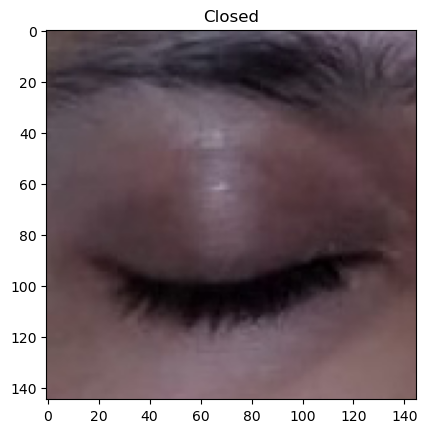

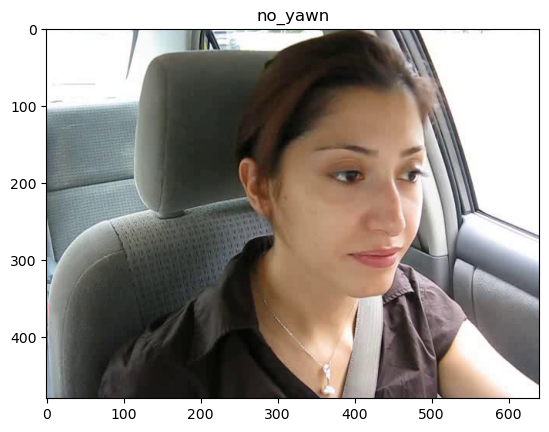

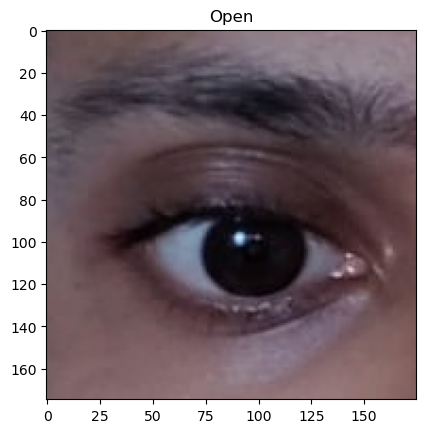

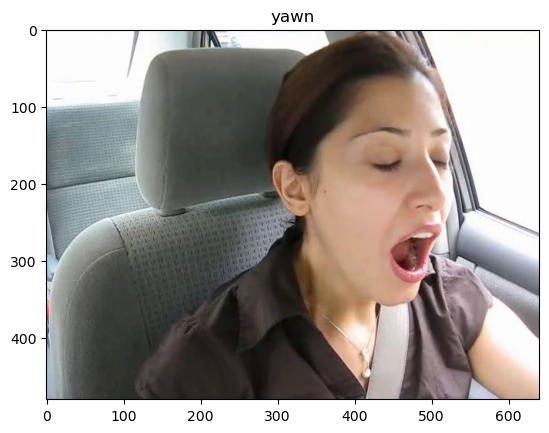

In [7]:
for i in classes:
    folder = os.path.join(train_dir, i)
    
    image = os.listdir(folder)[0]
    
    img = plt.imread(os.path.join(folder, image))
    
    plt.imshow(img)
    plt.title(i)
    plt.show()

In [8]:
folder = os.path.join(train_dir, "Closed")

image = os.listdir(folder)[0]

img = plt.imread(os.path.join(folder, image))

print(img.shape)


(145, 145, 3)


In [9]:
#IMAGE RESIZING 
img_resized = tf.image.resize(img, (128, 128))

print(img_resized.shape)

(128, 128, 3)


In [10]:
# IMAGE NORMALIZING
img_normalized = img_resized / 255.0

print(img_normalized.numpy().min())
print(img_normalized.numpy().max())

0.0
0.6476802


In [15]:
import tensorflow as tf

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(128, 128),
    batch_size=32
)

Found 2467 files belonging to 4 classes.


In [16]:
print(train_ds.class_names)

['Closed', 'Open', 'no_yawn', 'yawn']


In [17]:
for images, labels in train_ds.take(1):
    print(images.shape)
    print(labels.shape)

(32, 128, 128, 3)
(32,)


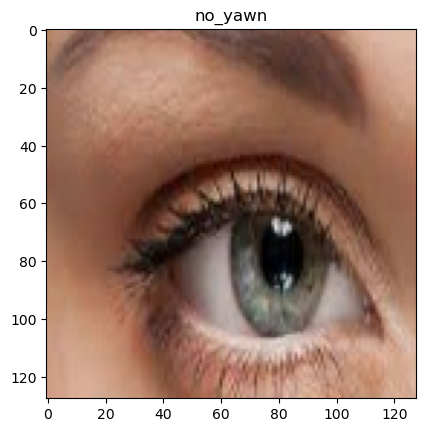

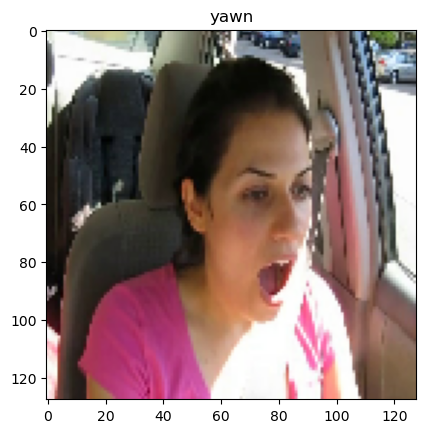

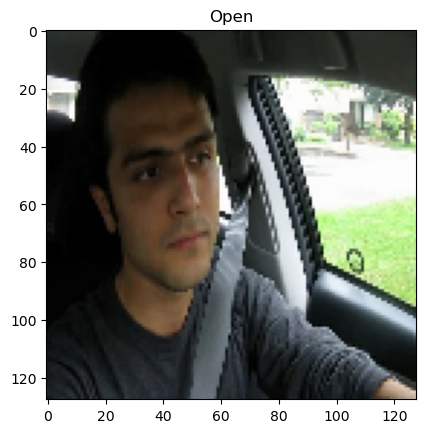

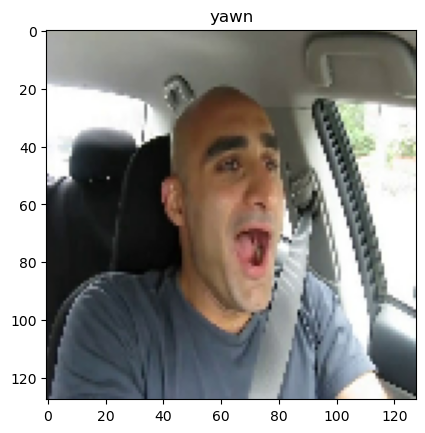

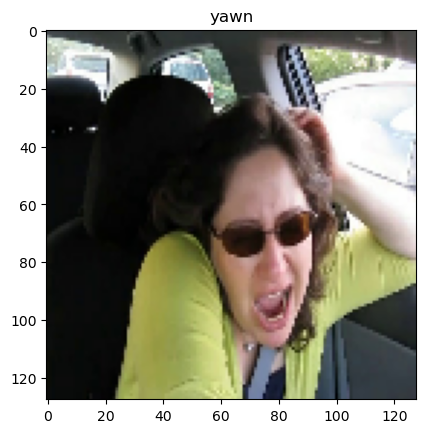

In [18]:
for images, labels in train_ds.take(1):
    for i in range(5):
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(classes[int(labels[i])])
        plt.show()

In [19]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

Found 2467 files belonging to 4 classes.
Using 1974 files for training.


In [20]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(128, 128),
    batch_size=32
)

Found 2467 files belonging to 4 classes.
Using 493 files for validation.


In [21]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(128, 128),
    batch_size=32,
    shuffle=False
)

Found 433 files belonging to 4 classes.


In [22]:
train_count = 0

for images, labels in train_ds:
    train_count = train_count + len(images)

print("Training images:", train_count)

Training images: 1974


In [23]:
val_count = 0

for images, labels in val_ds:
    val_count = val_count + len(images)

print("Validation images:", val_count)

Validation images: 493


In [24]:
test_count = 0

for images, labels in test_ds:
    test_count = test_count + len(images)

print("Testing images:", test_count)

Testing images: 433


In [25]:
class_count = np.zeros(4, dtype=int)

for images, labels in train_ds:
    for label in labels.numpy():
        class_count[label] = class_count[label] + 1

for i in range(4):
    print(train_ds.class_names[i], ":", class_count[i])

Closed : 510
Open : 479
no_yawn : 492
yawn : 493


In [26]:
train_ds = train_ds.map(lambda x, y: (x / 255.0, y))
val_ds = val_ds.map(lambda x, y: (x / 255.0, y))
test_ds = test_ds.map(lambda x, y: (x / 255.0, y))

In [27]:
#IMPORT CNN LAYERS  
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

In [28]:
#CREATE THE MODEL 
model = Sequential()

In [29]:
#ADDING FIRST CONVOLUTUIONAL LAYERS
model.add(Conv2D(32, (3,3), activation="relu", input_shape=(128,128,3)))

D:\python\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [31]:
#ADDING THE FIRST POOLING LAYER 
model.add(MaxPooling2D(pool_size=(2,2)))

In [32]:
#ADD SECOND CONVOLTIONAL  LAYERS 
model.add(Conv2D(64, (3,3), activation="relu"))

In [33]:
# ADDING SECOND POOLING LAYERS 
model.add(MaxPooling2D(pool_size=(2,2)))

In [34]:
#ADD FLATTEN LAYER
model.add(Flatten())

In [35]:
#ADD DENSE LAYER
model.add(Dense(128, activation="relu"))

In [36]:
#OUTPUT LAYER 
model.add(Dense(4, activation="softmax"))

In [37]:
#COMPILE CNN MODEL 
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [38]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 12544)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       1,605,760 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             516 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,625,668 (6.20 MB)

 Trainable params: 1,625,668 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

Epoch 1/15


D:\python\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


62/62 ━━━━━━━━━━━━━━━━━━━━ 16s 221ms/step - accuracy: 0.6920 - loss: 0.6451 - val_accuracy: 0.7850 - val_loss: 0.4160
Epoch 2/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 13s 211ms/step - accuracy: 0.8323 - loss: 0.3804 - val_accuracy: 0.8093 - val_loss: 0.3673
Epoch 3/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 21s 212ms/step - accuracy: 0.8551 - loss: 0.3142 - val_accuracy: 0.8316 - val_loss: 0.3310
Epoch 4/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 21s 214ms/step - accuracy: 0.8880 - loss: 0.2574 - val_accuracy: 0.8154 - val_loss: 0.3675
Epoch 5/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 21s 217ms/step - accuracy: 0.9043 - loss: 0.2255 - val_accuracy: 0.9006 - val_loss: 0.2375
Epoch 6/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 21s 215ms/step - accuracy: 0.9433 - loss: 0.1550 - val_accuracy: 0.8844 - val_loss: 0.2449
Epoch 7/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 13s 209ms/step - accuracy: 0.9509 - loss: 0.1413 - val_accuracy: 0.9229 - val_loss: 0.1931
Epoch 8/15
62/62 ━━━━━━━━━━━━━━━━━━━━ 13s 207ms/step - accuracy: 0.9605 - loss: 0.1054 - val_accuracy: 0.929

In [40]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.8868 - loss: 0.4194
Test Accuracy: 0.886836051940918
Test Loss: 0.4193858504295349


In [41]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

In [42]:
y_true = []

for images, labels in test_ds:
    for label in labels.numpy():
        y_true.append(label)

In [43]:
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images)
    
    for prediction in predictions:
        y_pred.append(np.argmax(prediction))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step


In [44]:
cm = confusion_matrix(y_true, y_pred)
print(cm)

[[106   3   0   0]
 [  7 102   0   0]
 [  0   0 108   1]
 [  0   0  38  68]]


In [48]:
class_names = ['Closed', 'Open', 'no_yawn', 'yawn']

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

      Closed       0.94      0.97      0.95       109
        Open       0.97      0.94      0.95       109
     no_yawn       0.74      0.99      0.85       109
        yawn       0.99      0.64      0.78       106

    accuracy                           0.89       433
   macro avg       0.91      0.89      0.88       433
weighted avg       0.91      0.89      0.88       433



In [55]:
image_path = r"C:/Users/SINAN/Pictures/Screenshots/Screenshot 2026-11-07 114525.png"

img = tf.keras.utils.load_img(
    image_path,
    target_size=(128, 128)
)

In [56]:
img_array = tf.keras.utils.img_to_array(img)

img_array = img_array / 255.0

In [57]:
img_array = np.expand_dims(img_array, axis=0)

In [58]:
prediction = model.predict(img_array)

predicted_class = np.argmax(prediction)

class_names = ['Closed', 'Open', 'no_yawn', 'yawn']

print("Predicted Class:", class_names[predicted_class])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
Predicted Class: no_yawn


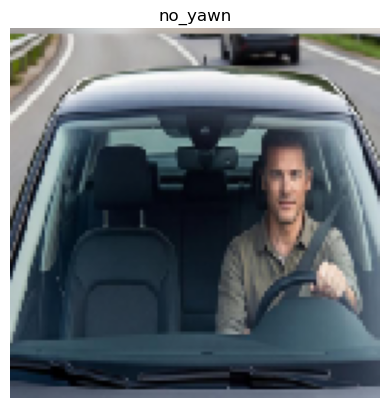

In [59]:
plt.imshow(img)
plt.title(class_names[predicted_class])
plt.axis("off")
plt.show()

In [1]:
import os
print(os.getcwd())

C:\Users\SINAN
